# PathSnap · Team 111 — Model training & model evaluation
**Deliverables:** *training code for every model experimented with* and *code for model comparison,
evaluation metrics, plots and confusion matrices.*

Input: `data/processed/fe/` from `02_feature_engineering.ipynb` (run 01 → 02 → 03; in Colab in one session).

| Step | What |
|---|---|
| 1 | Evaluation protocol and metrics (shared code) |
| 2–9 | **One section per model** (8 models, 7 algorithm families): config → 5-fold group CV → refit → student_test |
| 10 | Comparison table |
| 11 | Comparison plots, over-fitting check, confusion matrices |
| 12 | Training curves (only models that genuinely have them) |
| 13 | Model selection and saving |

## Step 0 — Setup

In [1]:
import os, time, json, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (f1_score, precision_score, recall_score, log_loss, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
if os.path.isdir("/content"):
    ROOT = "/content"


def find_raw(start_dirs):
    for start in start_dirs:
        for d, subdirs, _ in os.walk(start):
            if "train" in subdirs and "student_test" in subdirs:
                return d
            if d.count(os.sep) - start.count(os.sep) > 3:
                subdirs[:] = []
    return None


RAW = find_raw([d for d in [os.path.join(ROOT, "data", "raw"), ROOT] if os.path.isdir(d)])
FE = os.path.join(ROOT, "data", "processed", "fe")
RES = os.path.join(ROOT, "results"); os.makedirs(RES, exist_ok=True)
MOD = os.path.join(ROOT, "models", "notebook"); os.makedirs(MOD, exist_ok=True)
assert os.path.exists(os.path.join(FE, "train_features.pkl")), "Run 02_feature_engineering.ipynb first"
SEED = 111
warnings.filterwarnings("ignore", category=UserWarning)
FEATURES = pd.read_csv(os.path.join(RES, "fe_feature_list.csv")).feature.tolist()

tr = pd.read_pickle(os.path.join(FE, "train_features.pkl"))
te = pd.read_pickle(os.path.join(FE, "student_test_features.pkl"))
Xtr, ytr, gtr, folds = tr[FEATURES].values, tr.y.values, tr.trip.values, tr.fold.values
Xte, yte = te[FEATURES].values, te.y.values
# arcs of the student_test trips (needed for the route-continuity metric)
test_arcs = {t: np.loadtxt(os.path.join(RAW, "student_test", t, f"{t}.arcs"), dtype=int, ndmin=2) for t in te.trip.unique()}
print(f"train: {len(tr):,} rows, {tr.trip.nunique()} trips, 5 folds | student_test: {len(te):,} rows, {te.trip.nunique()} trips")
print(f"{len(FEATURES)} features")

train: 341,192 rows, 78 trips, 5 folds | student_test: 113,694 rows, 10 trips
22 features


## Step 1 — Evaluation protocol and metrics
* **Cross-validation:** 5-fold **GroupKFold** (folds from notebook 02, groups = trips) on the 78 training trips.
* **Development test:** fit on all training rows → evaluate on the 10 **student_test** trips (every observation).
* **Candidate-level metrics** (threshold 0.5): macro **precision / recall / F1**, **log loss**, confusion matrix.
  Macro F1 is the **primary selection metric** (classes are imbalanced: ~17% positives).
* **Observation-level Top-1 accuracy:** for each GPS point, the highest-scoring candidate = prediction.
* **Route continuity:** share of consecutive points whose predicted arcs are the same or directly connected.
* **Time:** training time and inference time (ms per 1,000 GPS points).

In [2]:
def top1_accuracy(df, p):
    d = df[["trip", "pt", "y"]].copy(); d["p"] = p
    best = d.loc[d.groupby(["trip", "pt"]).p.idxmax()]
    return float(best.y.mean())


def route_continuity(df, p):
    d = df[["trip", "pt", "arc"]].copy(); d["p"] = p
    best = d.loc[d.groupby(["trip", "pt"]).p.idxmax()].sort_values(["trip", "pt"])
    scores = []
    for t, g in best.groupby("trip"):
        a, b = g.arc.values[:-1], g.arc.values[1:]
        arcs = test_arcs[t]
        scores.append(((a == b) | (arcs[a, 1] == arcs[b, 0])).mean())
    return float(np.mean(scores))


def candidate_metrics(y, p):
    yhat = (p >= 0.5).astype(int)
    return dict(macro_f1=f1_score(y, yhat, average="macro"),
                macro_precision=precision_score(y, yhat, average="macro", zero_division=0),
                macro_recall=recall_score(y, yhat, average="macro", zero_division=0),
                log_loss=log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]))


RESULTS, PREDS, FITTED = [], {}, {}


def run_model(name, family, config, make_model, subsample=None):
    """5-fold group CV on train, refit on all train, evaluate on student_test."""
    rng = np.random.RandomState(SEED)
    cv_f1, cv_top1, cv_ll = [], [], []
    for k in range(5):
        a, b = folds != k, folds == k
        Xa, ya = Xtr[a], ytr[a]
        if subsample and len(Xa) > subsample:
            i = rng.choice(len(Xa), subsample, replace=False); Xa, ya = Xa[i], ya[i]
        m = make_model().fit(Xa, ya)
        p = m.predict_proba(Xtr[b])[:, 1]
        cv_f1.append(f1_score(ytr[b], (p >= .5).astype(int), average="macro"))
        cv_top1.append(top1_accuracy(tr[b], p)); cv_ll.append(log_loss(ytr[b], np.clip(p, 1e-6, 1 - 1e-6)))
    Xa, ya = Xtr, ytr
    if subsample and len(Xa) > subsample:
        i = rng.choice(len(Xa), subsample, replace=False); Xa, ya = Xa[i], ya[i]
    t0 = time.time(); m = make_model().fit(Xa, ya); train_s = time.time() - t0
    t0 = time.time(); p = m.predict_proba(Xte)[:, 1]; inf_s = time.time() - t0
    n_obs = te.groupby("trip").pt.nunique().sum()
    row = dict(model=name, family=family, config=config,
               cv_macro_f1=np.mean(cv_f1), cv_macro_f1_std=np.std(cv_f1), cv_top1=np.mean(cv_top1), cv_log_loss=np.mean(cv_ll),
               train_top1_in_sample=top1_accuracy(tr, m.predict_proba(Xtr)[:, 1]),
               test_top1=top1_accuracy(te, p), **{"test_" + k: v for k, v in candidate_metrics(yte, p).items()},
               test_route_continuity=route_continuity(te, p),
               train_time_s=train_s, inference_ms_per_1k_points=1e6 * inf_s / n_obs)
    RESULTS[:] = [r for r in RESULTS if r["model"] != name] + [row]
    PREDS[name] = p; FITTED[name] = m
    print(f"{name}: CV macro F1 {row['cv_macro_f1']:.4f} ± {row['cv_macro_f1_std']:.4f} | "
          f"test Top-1 {row['test_top1']:.4f} | test macro F1 {row['test_macro_f1']:.4f} | "
          f"log loss {row['test_log_loss']:.4f} | train {train_s:.1f}s")
    return pd.DataFrame({"fold": range(5), "macro_f1": cv_f1, "top1": cv_top1, "log_loss": cv_ll}).round(4)

## Step 2 — Model 1: Logistic Regression (linear)
Linear decision boundary on standardised features; outputs calibrated probabilities. Objective: L2-regularised
log loss. Scaler is inside the pipeline → fitted on the training folds only.

In [3]:
run_model("LogReg", "Linear", "StandardScaler + LogisticRegression(C=1.0, L2)",
          lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=500)))

LogReg: CV macro F1 0.9105 ± 0.0167 | test Top-1 0.8678 | test macro F1 0.9057 | log loss 0.1344 | train 1.0s


,fold,macro_f1,top1,log_loss
0,0,0.8864,0.8546,0.1773
1,1,0.9312,0.9196,0.1106
2,2,0.8975,0.8779,0.1636
3,3,0.9253,0.9128,0.1169
4,4,0.9122,0.8909,0.1266


## Step 3 — Model 2: Gaussian Naive Bayes (probabilistic)
Assumes features are independent and Gaussian per class — a fast baseline; our distance features are strongly
correlated, so we expect poor probability calibration.

In [4]:
run_model("GaussianNB", "Probabilistic", "GaussianNB(var_smoothing=1e-9)", lambda: GaussianNB())

GaussianNB: CV macro F1 0.8588 ± 0.0127 | test Top-1 0.8549 | test macro F1 0.8432 | log loss 0.6293 | train 0.1s


,fold,macro_f1,top1,log_loss
0,0,0.8400,0.8527,0.7270
1,1,0.8700,0.9037,0.4741
2,2,0.8485,0.8618,0.7382
3,3,0.8733,0.8968,0.5306
4,4,0.8622,0.8806,0.4433


## Step 4 — Model 3: K-Nearest Neighbours (instance-based)
Distance-weighted vote of the 25 nearest training rows in standardised feature space. No training loss;
prediction is expensive, so it is fitted on a 60,000-row subsample.

In [5]:
run_model("KNN", "Instance-based", "StandardScaler + KNN(k=25, distance-weighted), 60k-row subsample",
          lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25, weights="distance", n_jobs=-1)),
          subsample=60000)

KNN: CV macro F1 0.9192 ± 0.0150 | test Top-1 0.8670 | test macro F1 0.9155 | log loss 0.1592 | train 0.0s


,fold,macro_f1,top1,log_loss
0,0,0.9038,0.8608,0.1918
1,1,0.9401,0.9252,0.1116
2,2,0.9044,0.8628,0.1833
3,3,0.9337,0.9151,0.1250
4,4,0.9139,0.8812,0.1532


## Step 5 — Model 4: Decision Tree
Axis-aligned threshold rules (Gini impurity). Depth limit 12 and min 20 samples per leaf against over-fitting.

In [6]:
run_model("DecisionTree", "Tree", "DecisionTree(max_depth=12, min_samples_leaf=20)",
          lambda: DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=SEED))

DecisionTree: CV macro F1 0.9291 ± 0.0175 | test Top-1 0.8780 | test macro F1 0.9241 | log loss 0.1387 | train 5.2s


,fold,macro_f1,top1,log_loss
0,0,0.9155,0.8739,0.1881
1,1,0.9519,0.9290,0.0986
2,2,0.9088,0.8771,0.1927
3,3,0.9478,0.9281,0.1051
4,4,0.9213,0.8800,0.1235


## Step 6 — Model 5: Random Forest (bagging ensemble)
100 trees on bootstrap samples with random feature subsets; averaging reduces variance.

In [7]:
run_model("RandomForest", "Bagging ensemble", "100 trees, max_depth=20, min_samples_leaf=5, max_features=sqrt",
          lambda: RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=5, n_jobs=-1, random_state=SEED))

RandomForest: CV macro F1 0.9398 ± 0.0150 | test Top-1 0.8936 | test macro F1 0.9354 | log loss 0.0907 | train 41.7s


,fold,macro_f1,top1,log_loss
0,0,0.9218,0.8767,0.1138
1,1,0.9613,0.9382,0.0605
2,2,0.9269,0.8871,0.1116
3,3,0.9527,0.9317,0.0719
4,4,0.9364,0.9024,0.0893


## Step 7 — Model 6: Extra Trees (randomised ensemble)
Like Random Forest but with random split thresholds → even lower variance, faster training.

In [8]:
run_model("ExtraTrees", "Randomised ensemble", "150 trees, max_depth=20, min_samples_leaf=5",
          lambda: ExtraTreesClassifier(n_estimators=150, max_depth=20, min_samples_leaf=5, n_jobs=-1, random_state=SEED))

ExtraTrees: CV macro F1 0.9333 ± 0.0150 | test Top-1 0.8841 | test macro F1 0.9258 | log loss 0.0993 | train 10.3s


,fold,macro_f1,top1,log_loss
0,0,0.9146,0.8716,0.1214
1,1,0.9557,0.9330,0.0700
2,2,0.9220,0.8840,0.1207
3,3,0.9449,0.9257,0.0802
4,4,0.9296,0.9007,0.1000


## Step 8 — Model 7: Histogram Gradient Boosting (boosting)
Trees added sequentially, each correcting the previous ones' errors on the log-loss gradient; features are
binned into histograms → fast on large tables. Untuned defaults here (tuned in the Bayesian optimisation stage).

In [9]:
run_model("HistGB", "Boosting", "HistGradientBoosting(lr=0.1, max_iter=200, max_leaf_nodes=31) — untuned",
          lambda: HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200, max_leaf_nodes=31, random_state=SEED))

HistGB: CV macro F1 0.9386 ± 0.0144 | test Top-1 0.8847 | test macro F1 0.9298 | log loss 0.0974 | train 2.1s


,fold,macro_f1,top1,log_loss
0,0,0.9205,0.8731,0.1219
1,1,0.9576,0.9375,0.0645
2,2,0.9273,0.8883,0.1109
3,3,0.9530,0.9308,0.0741
4,4,0.9347,0.8964,0.0997


## Step 9 — Model 8: Multi-layer Perceptron (neural network)
Two hidden layers (64, 32), ReLU, Adam on binary cross-entropy, L2 alpha=1e-4, early stopping;
fitted on a 200,000-row subsample to keep training time reasonable.

In [10]:
run_model("MLP", "Neural network", "StandardScaler + MLP(64,32) ReLU, Adam, alpha=1e-4, early stopping, 200k rows",
          lambda: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-4, max_iter=60,
                                                                early_stopping=True, random_state=SEED)),
          subsample=200000)

MLP: CV macro F1 0.9328 ± 0.0130 | test Top-1 0.8788 | test macro F1 0.9259 | log loss 0.1086 | train 15.6s


,fold,macro_f1,top1,log_loss
0,0,0.9170,0.8725,0.1364
1,1,0.9517,0.9325,0.0840
2,2,0.9221,0.8851,0.1263
3,3,0.9433,0.9228,0.0984
4,4,0.9299,0.8954,0.1003


## Step 10 — Comparison table

In [11]:
cmp_ = pd.DataFrame(RESULTS)
cmp_.to_csv(os.path.join(RES, "nb_model_comparison.csv"), index=False)
show = cmp_[["model", "family", "cv_macro_f1", "cv_macro_f1_std", "cv_top1", "test_top1", "test_macro_f1",
             "test_macro_precision", "test_macro_recall", "test_log_loss", "test_route_continuity",
             "train_top1_in_sample", "train_time_s", "inference_ms_per_1k_points"]]
show.round(4)

,model,family,cv_macro_f1,cv_macro_f1_std,cv_top1,test_top1,test_macro_f1,test_macro_precision,test_macro_recall,test_log_loss,test_route_continuity,train_top1_in_sample,train_time_s,inference_ms_per_1k_points
0,LogReg,Linear,0.9105,0.0167,0.8912,0.8678,0.9057,0.9065,0.9049,0.1344,0.9190,0.8905,1.0192,0.5823
1,GaussianNB,Probabilistic,0.8588,0.0127,0.8791,0.8549,0.8432,0.8098,0.9006,0.6293,0.9199,0.8791,0.0893,1.5592
2,KNN,Instance-based,0.9192,0.0150,0.8890,0.8670,0.9155,0.9221,0.9093,0.1592,0.9236,0.9331,0.0197,527.2675
3,DecisionTree,Tree,0.9291,0.0175,0.8976,0.8780,0.9241,0.9238,0.9243,0.1387,0.9283,0.9356,5.1834,0.4313
4,RandomForest,Bagging ensemble,0.9398,0.0150,0.9072,0.8936,0.9354,0.9405,0.9304,0.0907,0.9357,0.9674,41.6510,18.8128
5,ExtraTrees,Randomised ensemble,0.9333,0.0150,0.9030,0.8841,0.9258,0.9408,0.9124,0.0993,0.9286,0.9266,10.2738,33.3151
6,HistGB,Boosting,0.9386,0.0144,0.9052,0.8847,0.9298,0.9285,0.9311,0.0974,0.9329,0.9270,2.1032,6.6765
7,MLP,Neural network,0.9328,0.0130,0.9017,0.8788,0.9259,0.9267,0.9250,0.1086,0.9331,0.9254,15.6285,3.8041


## Step 11 — Comparison plots

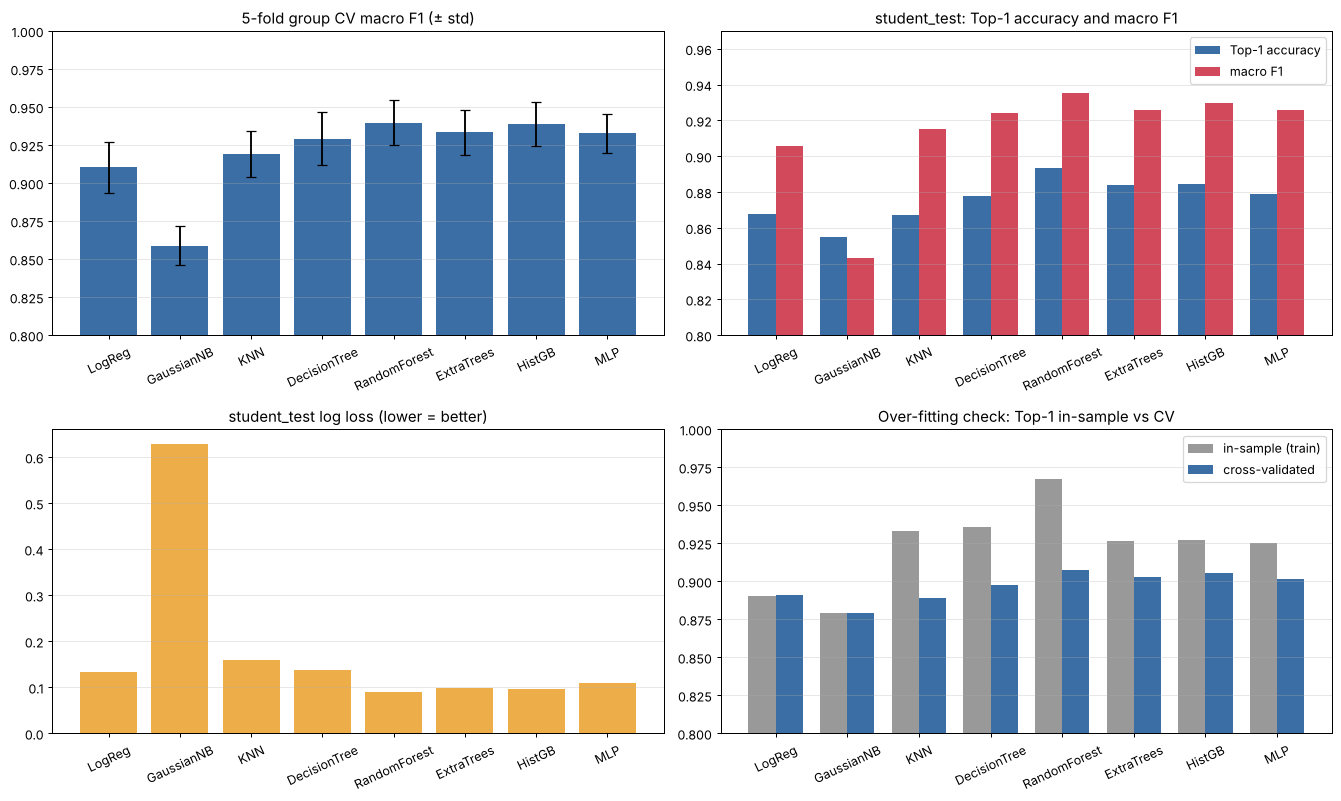

In [12]:
x = np.arange(len(cmp_)); w = .38
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
ax[0, 0].bar(x, cmp_.cv_macro_f1, yerr=cmp_.cv_macro_f1_std, capsize=4, color="#3b6ea5")
ax[0, 0].set(title="5-fold group CV macro F1 (± std)", ylim=(0.8, 1.0))
ax[0, 1].bar(x - w / 2, cmp_.test_top1, w, label="Top-1 accuracy", color="#3b6ea5")
ax[0, 1].bar(x + w / 2, cmp_.test_macro_f1, w, label="macro F1", color="#d1495b")
ax[0, 1].set(title="student_test: Top-1 accuracy and macro F1", ylim=(0.8, 0.97)); ax[0, 1].legend()
ax[1, 0].bar(x, cmp_.test_log_loss, color="#edae49"); ax[1, 0].set(title="student_test log loss (lower = better)")
ax[1, 1].bar(x - w / 2, cmp_.train_top1_in_sample, w, label="in-sample (train)", color="#999999")
ax[1, 1].bar(x + w / 2, cmp_.cv_top1, w, label="cross-validated", color="#3b6ea5")
ax[1, 1].set(title="Over-fitting check: Top-1 in-sample vs CV", ylim=(0.8, 1.0)); ax[1, 1].legend()
for a in ax.ravel():
    a.set_xticks(x); a.set_xticklabels(cmp_.model, rotation=25); a.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(RES, "nb_model_comparison.png"), dpi=110); plt.show()

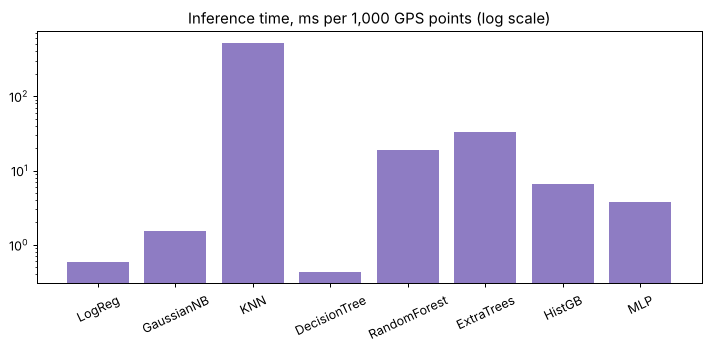

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x, cmp_.inference_ms_per_1k_points, color="#8e7cc3"); ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels(cmp_.model, rotation=25); ax.set(title="Inference time, ms per 1,000 GPS points (log scale)")
plt.tight_layout(); plt.show()

### Confusion matrices (student_test, candidate level, threshold 0.5)

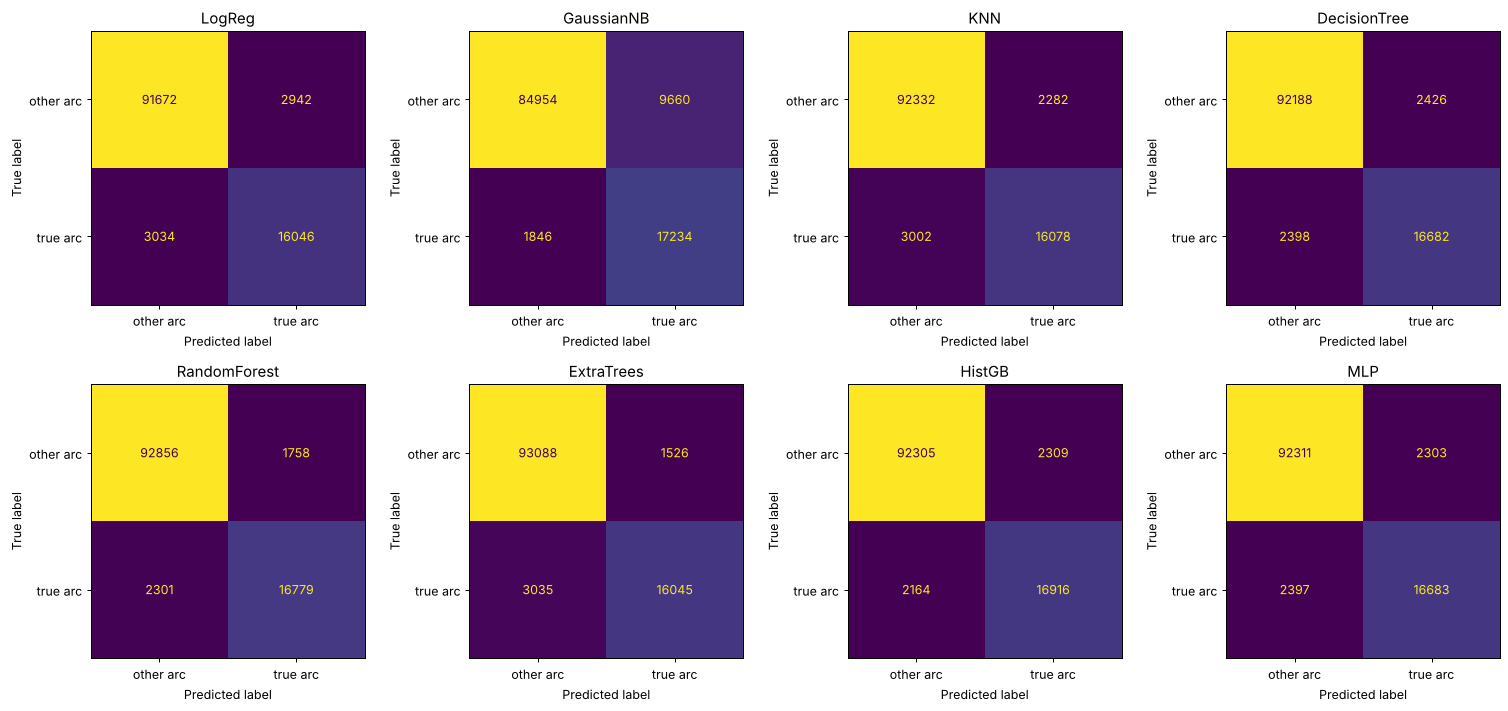

In [14]:
fig, axs = plt.subplots(2, 4, figsize=(17, 8))
for a, name in zip(axs.ravel(), cmp_.model):
    ConfusionMatrixDisplay(confusion_matrix(yte, PREDS[name] >= .5), display_labels=["other arc", "true arc"]).plot(
        ax=a, colorbar=False, values_format="d")
    a.set_title(name)
plt.tight_layout(); plt.savefig(os.path.join(RES, "nb_confusion_matrices.png"), dpi=100); plt.show()

## Step 12 — Training curves (only for models that produce them)
The MLP (epochs) and HistGB (boosting iterations) have genuine training histories; the other models do not,
so no curves are drawn for them. Validation = 12 held-out training trips.

MLP final train/val log loss 0.0821/0.0837; HistGB 0.0652/0.0723


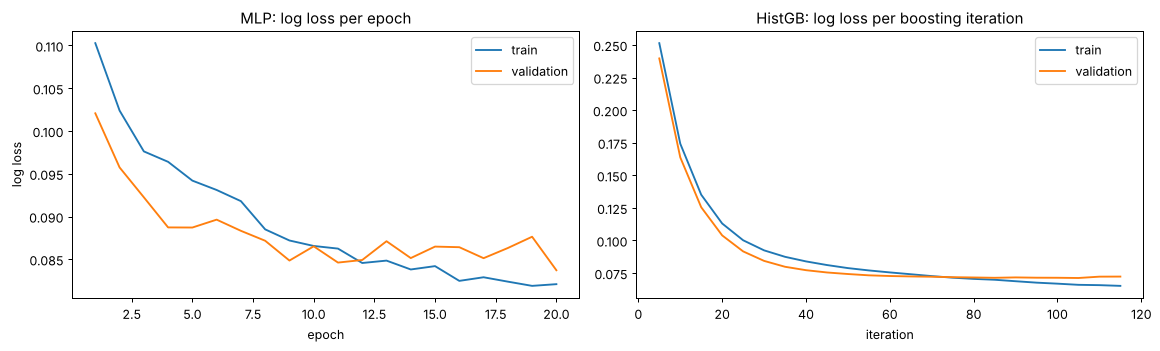

In [15]:
from sklearn.metrics import log_loss as LL
rng = np.random.RandomState(SEED)
val_trips = rng.choice(np.unique(gtr), 12, replace=False); va = np.isin(gtr, val_trips)
sc = StandardScaler().fit(Xtr[~va]); Xa, Xv = sc.transform(Xtr[~va]), sc.transform(Xtr[va]); ya, yv = ytr[~va], ytr[va]
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-4, random_state=SEED, batch_size=512)
hist = []
for ep in range(1, 21):
    perm = rng.permutation(len(Xa))
    for s in range(0, len(Xa), 20000):
        j = perm[s:s + 20000]; mlp.partial_fit(Xa[j], ya[j], classes=[0, 1])
    hist.append((ep, LL(ya, mlp.predict_proba(Xa)[:, 1]), LL(yv, mlp.predict_proba(Xv)[:, 1])))
hist = np.array(hist)
hgb = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200, max_leaf_nodes=31, random_state=SEED).fit(Xtr[~va], ya)
st = [(i + 1, LL(ya, pa[:, 1]), LL(yv, pv[:, 1])) for i, (pa, pv) in
      enumerate(zip(hgb.staged_predict_proba(Xtr[~va]), hgb.staged_predict_proba(Xtr[va]))) if i % 5 == 4]
st = np.array(st)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist[:, 0], hist[:, 1], label="train"); ax[0].plot(hist[:, 0], hist[:, 2], label="validation")
ax[0].set(title="MLP: log loss per epoch", xlabel="epoch", ylabel="log loss"); ax[0].legend()
ax[1].plot(st[:, 0], st[:, 1], label="train"); ax[1].plot(st[:, 0], st[:, 2], label="validation")
ax[1].set(title="HistGB: log loss per boosting iteration", xlabel="iteration"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"MLP final train/val log loss {hist[-1,1]:.4f}/{hist[-1,2]:.4f}; HistGB {st[-1,1]:.4f}/{st[-1,2]:.4f}")

## Step 13 — Model selection
Rank by the primary metric (CV macro F1). Models within **0.002** of the best CV macro F1 are treated as a tie
(smaller than the fold-to-fold spread); the tie is broken by the **smaller over-fitting gap**
(in-sample Top-1 − CV Top-1), then lower log loss (the HMM uses the probabilities), then faster training.

In [16]:
best_f1 = cmp_.cv_macro_f1.max()
cmp_["overfit_gap"] = cmp_.train_top1_in_sample - cmp_.cv_top1
tied = cmp_[cmp_.cv_macro_f1 >= best_f1 - 0.002].copy()
print("models tied on CV macro F1 (within 0.002 of the best):")
print(tied[["model", "cv_macro_f1", "overfit_gap", "test_log_loss", "train_time_s"]].round(4).to_string(index=False))
chosen = tied.sort_values(["overfit_gap", "test_log_loss", "train_time_s"]).iloc[0].model
print(f"\nselected for tuning: {chosen}")
joblib.dump(FITTED[chosen], os.path.join(MOD, f"{chosen}_untuned.joblib"))
json.dump(dict(selected=chosen, features=FEATURES, seed=SEED), open(os.path.join(MOD, "selection.json"), "w"), indent=2)

models tied on CV macro F1 (within 0.002 of the best):
       model  cv_macro_f1  overfit_gap  test_log_loss  train_time_s
RandomForest       0.9398       0.0602         0.0907       41.6510
      HistGB       0.9386       0.0218         0.0974        2.1032

selected for tuning: HistGB


## Summary
- 8 models from 7 families trained with identical folds, features and seed.
- Saved: `results/nb_model_comparison.csv`, comparison plots and confusion matrices, the selected model in
  `models/notebook/`.
- Tree ensembles (Random Forest, HistGB) lead; Naive Bayes is weakest and badly calibrated; KNN is slowest at inference.
- **Next stage:** Bayesian hyperparameter optimisation of the selected model, then HMM/Viterbi decoding.